<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 2 · Sesión 1: Variables aleatorias, probabilidad condicional y esperanza</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: Bernoulli y Binomial, Bayes, pérdida esperada y distribución de pérdidas con correlación (Vasicek)</div>
</div>

## Objetivos de la sesión (2 horas)

1. Modelar el incumplimiento como una **variable aleatoria Bernoulli** y la cantidad de incumplimientos como una **Binomial**.
2. Calcular **probabilidades condicionales** y aplicar el **teorema de Bayes** a decisiones de crédito.
3. Usar **esperanza y varianza** para pasar de la PD individual a la **pérdida esperada** de una cartera.
4. Simular la **distribución de pérdidas** con y sin **correlación de incumplimiento**, y entender por qué la correlación cambia la cola (capital).

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 20 min | Variables aleatorias, Bernoulli y Binomial |
| 2 | 30 min | Probabilidad condicional, independencia y Bayes |
| 3 | 30 min | Esperanza, varianza y pérdida esperada |
| 4 | 30 min | Monte Carlo de pérdidas y correlación (modelo de un factor) |
| 5 | 10 min | Ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

from scipy import stats
app = pd.read_csv(DATA / "hc_application_sintetico.csv")
app["EDAD"] = -app.DAYS_BIRTH / 365.25

## 1. El incumplimiento como variable aleatoria

Para un cliente $i$ definimos $D_i \in \{0, 1\}$ (1 = incumple en el horizonte). Entonces:
$$D_i \sim \text{Bernoulli}(p_i), \qquad P(D_i = 1) = p_i = PD_i$$
$$E[D_i] = p_i, \qquad \text{Var}(D_i) = p_i(1 - p_i)$$

En una cartera de $n$ clientes **independientes** con la misma PD, el número de incumplimientos $N = \sum D_i$ es:
$$N \sim \text{Binomial}(n, p), \qquad E[N] = np, \qquad \text{Var}(N) = np(1-p)$$

PD observada de la cartera: 0.0798
Varianza de D_i: 0.0734  |  desviación: 0.2710


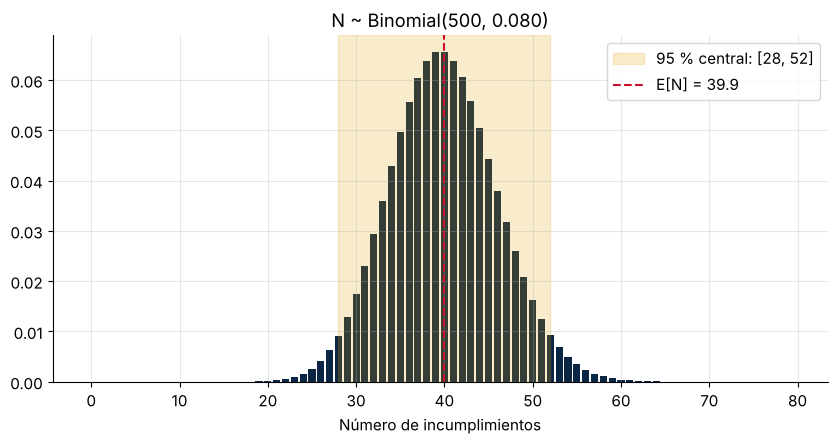

P(N >= 55) = 0.0104


In [2]:
p_hat = app.TARGET.mean()
print(f"PD observada de la cartera: {p_hat:.4f}")
print(f"Varianza de D_i: {p_hat * (1 - p_hat):.4f}  |  desviación: {np.sqrt(p_hat * (1 - p_hat)):.4f}")

# Una agencia coloca 500 créditos por mes. ¿Cuántos incumplimientos esperar?
n = 500
k = np.arange(0, 80)
pmf = stats.binom.pmf(k, n, p_hat)
fig, ax = plt.subplots()
ax.bar(k, pmf, color=AZUL)
lo, hi = stats.binom.ppf([0.025, 0.975], n, p_hat)
ax.axvspan(lo, hi, color=ORO, alpha=.2, label=f"95 % central: [{lo:.0f}, {hi:.0f}]")
ax.axvline(n * p_hat, color=ROJO, ls="--", label=f"E[N] = {n * p_hat:.1f}")
ax.set_title(f"N ~ Binomial({n}, {p_hat:.3f})"); ax.set_xlabel("Número de incumplimientos"); ax.legend(); plt.show()
print(f"P(N >= 55) = {1 - stats.binom.cdf(54, n, p_hat):.4f}")

> **Pregunta para la clase:** una agencia reporta 55 incumplimientos en 500 créditos. ¿Es "mala suerte" o una señal? ¿Qué supuesto de la Binomial podría estar fallando? *(Respuesta: independencia y PD homogénea. Lo retomamos en la Sección 4.)*

## 2. Probabilidad condicional
$$P(D = 1 \mid X = x) = \frac{P(D = 1, X = x)}{P(X = x)}$$
Toda **PD por segmento** es una probabilidad condicional. Un modelo de PD, como la regresión logística del Módulo 3, es simplemente una forma suave de estimar $P(D=1 \mid X)$ cuando $X$ tiene muchas dimensiones.

In [3]:
tab = pd.crosstab(app.NAME_EDUCATION_TYPE, app.TARGET, margins=True)
tab.columns = ["No incumple", "Incumple", "Total"]
tab["P(D=1 | educación)"] = tab["Incumple"] / tab["Total"]
tab["P(educación | D=1)"] = tab["Incumple"] / tab.loc["All", "Incumple"]
tab["P(educación)"] = tab["Total"] / tab.loc["All", "Total"]
tab.style.format({c: "{:.2%}" for c in tab.columns if c.startswith("P(")})

,No incumple,Incumple,Total,P(D=1 | educación),P(educación | D=1),P(educación)
NAME_EDUCATION_TYPE,,,,,,
Academic degree,18,1,19,5.26%,0.02%,0.03%
Higher education,13863,766,14629,5.24%,15.98%,24.36%
Incomplete higher,1822,136,1958,6.95%,2.84%,3.26%
Lower secondary,722,88,810,10.86%,1.84%,1.35%
Secondary / secondary special,38841,3803,42644,8.92%,79.33%,71.00%
All,55266,4794,60060,7.98%,100.00%,100.00%


**Ojo con la confusión clásica:** $P(D=1 \mid \text{Secundaria})$ ≠ $P(\text{Secundaria} \mid D=1)$. La mayoría de los morosos tiene educación secundaria porque **la mayoría de los clientes** tiene secundaria, no necesariamente porque ese grupo sea el más riesgoso.

### Independencia
$D$ y $X$ son independientes si $P(D=1 \mid X) = P(D=1)$. Si una variable es casi independiente del incumplimiento, **no discrimina**. Ésta es la intuición detrás del *Information Value* (Módulo 3).

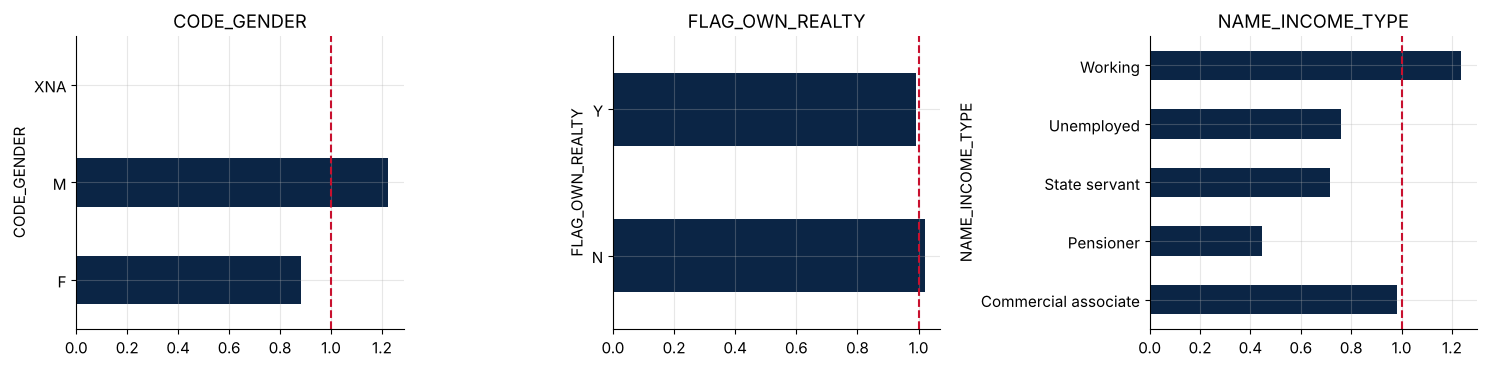

In [4]:
def lift(col):
    g = app.groupby(col).TARGET.mean() / app.TARGET.mean()
    return g.rename("lift = P(D|x)/P(D)")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, c in zip(ax, ["CODE_GENDER", "FLAG_OWN_REALTY", "NAME_INCOME_TYPE"]):
    lift(c).plot(kind="barh", ax=a, color=AZUL); a.axvline(1, color=ROJO, ls="--"); a.set_title(c)
plt.tight_layout(); plt.show()

### Teorema de Bayes en una alerta de fraude / riesgo
$$P(D=1 \mid A) = \frac{P(A \mid D=1) \, P(D=1)}{P(A \mid D=1)P(D=1) + P(A \mid D=0)P(D=0)}$$

Supongamos una **alerta temprana** (p. ej., el cliente usó más del 90 % de su línea en otros bancos) que se activa en el 60 % de los futuros morosos y en el 15 % de los buenos. Si la PD base es 8 %, ¿cuál es la PD dado que se activa la alerta?

PD | alerta = 25.81%   (vs. prior 8 %)


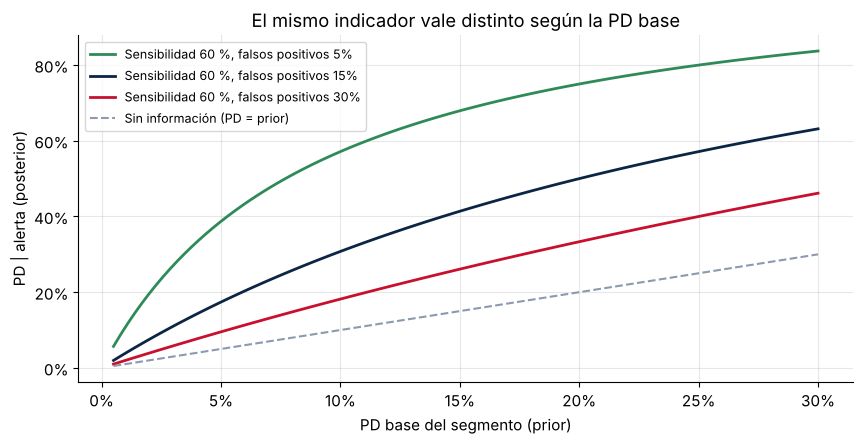

In [5]:
def bayes(sens, fpr, prior):
    return sens * prior / (sens * prior + fpr * (1 - prior))

print(f"PD | alerta = {bayes(0.60, 0.15, 0.08):.2%}   (vs. prior 8 %)")
priors = np.linspace(0.005, 0.30, 100)
fig, ax = plt.subplots()
for fpr, c in [(0.05, VERDE), (0.15, AZUL), (0.30, ROJO)]:
    ax.plot(priors, bayes(0.6, fpr, priors), color=c, lw=2, label=f"Sensibilidad 60 %, falsos positivos {fpr:.0%}")
ax.plot(priors, priors, color=GRIS, ls="--", label="Sin información (PD = prior)")
ax.set_xlabel("PD base del segmento (prior)"); ax.set_ylabel("PD | alerta (posterior)"); ax.legend(fontsize=9)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}")); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_title("El mismo indicador vale distinto según la PD base"); plt.show()

**Lectura:** en segmentos de PD baja (p. ej., hipotecario), incluso una buena alerta genera **muchos falsos positivos**. Esto explica por qué las reglas de cobranza preventiva se calibran por segmento. *(Volveremos a Bayes en el Módulo 10.)*

## 3. Esperanza, varianza y pérdida esperada
La pérdida de un crédito es $L_i = D_i \times LGD_i \times EAD_i$. Si LGD y EAD son conocidas (o independientes de $D_i$):
$$E[L_i] = PD_i \times LGD_i \times EAD_i \qquad\qquad E\Big[\sum_i L_i\Big] = \sum_i PD_i \cdot LGD_i \cdot EAD_i$$

La **linealidad de la esperanza** no requiere independencia: la pérdida esperada de la cartera es la suma de las pérdidas esperadas individuales. **La varianza sí depende de la correlación:**
$$\text{Var}\Big(\sum L_i\Big) = \sum_i \text{Var}(L_i) + \sum_{i \ne j} \text{Cov}(L_i, L_j)$$

In [6]:
# PD individual: usamos un modelo simple de 3 variables solo como insumo (se estudia en el Módulo 3)
from sklearn.linear_model import LogisticRegression
X = app[["EXT_SOURCE_2", "EXT_SOURCE_3", "EDAD"]].fillna(app[["EXT_SOURCE_2", "EXT_SOURCE_3", "EDAD"]].median())
app["PD"] = LogisticRegression(max_iter=1000).fit(X, app.TARGET).predict_proba(X)[:, 1]
app["LGD"] = 0.65
app["EAD"] = app.AMT_CREDIT * 0.85
app["EL"] = app.PD * app.LGD * app.EAD
print(f"Exposición total: S/ {app.EAD.sum() / 1e6:,.1f} MM")
print(f"Pérdida esperada: S/ {app.EL.sum() / 1e6:,.2f} MM  ->  {app.EL.sum() / app.EAD.sum():.2%} de la exposición")
app.assign(dec=pd.qcut(app.PD, 10, labels=False) + 1).groupby("dec").agg(PD_media=("PD", "mean"), tasa_obs=("TARGET", "mean"),
    EAD=("EAD", "sum"), EL=("EL", "sum")).assign(EL_pct=lambda d: d.EL / d.EL.sum()).style.format(
    {"PD_media": "{:.2%}", "tasa_obs": "{:.2%}", "EAD": "{:,.0f}", "EL": "{:,.0f}", "EL_pct": "{:.1%}"})

Exposición total: S/ 1,646.9 MM
Pérdida esperada: S/ 89.39 MM  ->  5.43% de la exposición


,PD_media,tasa_obs,EAD,EL,EL_pct
dec,,,,,
1,1.37%,1.23%,"143,266,395","1,278,770",1.4%
2,2.24%,1.91%,"152,435,260","2,227,436",2.5%
3,3.04%,2.96%,"159,093,140","3,145,474",3.5%
4,3.91%,4.31%,"161,930,100","4,115,812",4.6%
5,4.95%,5.54%,"168,452,150","5,421,946",6.1%
6,6.25%,6.29%,"167,755,490","6,822,238",7.6%
7,7.98%,7.96%,"168,282,830","8,740,566",9.8%
8,10.43%,10.46%,"170,483,735","11,551,992",12.9%
9,14.46%,14.17%,"173,953,435","16,355,692",18.3%


**Observa:** el decil más riesgoso concentra una fracción de la pérdida esperada muy superior a su 10 % de clientes. Ésa es la lógica de priorizar acciones (cobranza, límites, precio) por **pérdida esperada** y no por número de clientes.

## 4. Distribución de pérdidas: independencia vs. correlación
Los incumplimientos **no son independientes**: comparten el ciclo económico. El **modelo de un factor (Vasicek)**, base de la fórmula de capital IRB de Basilea, lo representa así:
$$Z_i = \sqrt{\rho}\, M + \sqrt{1-\rho}\, \varepsilon_i, \qquad D_i = \mathbb{1}\{Z_i < \Phi^{-1}(PD_i)\}$$
donde $M \sim N(0,1)$ es el factor sistémico (economía), $\varepsilon_i$ es idiosincrático y $\rho$ es la correlación de activos. Basilea usa $\rho$ entre 3 % y 16 % para minorista "otros" y 15 % para hipotecario.

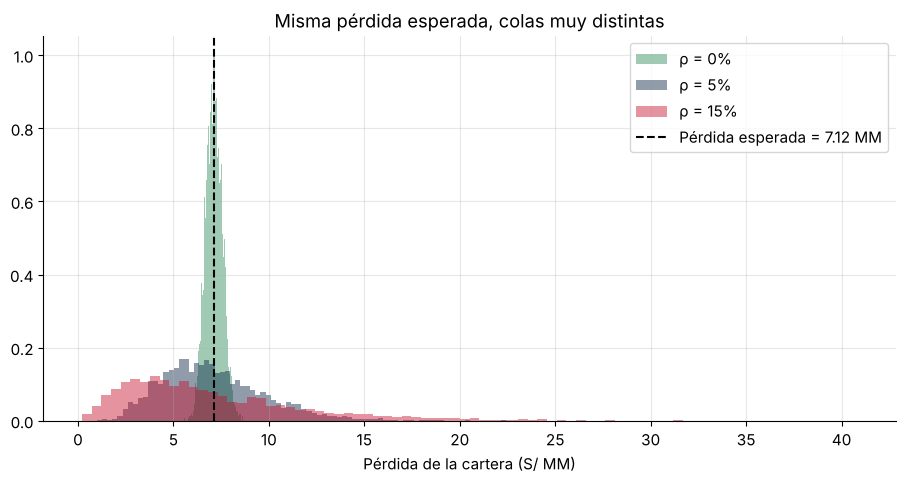

,Media,Desv. est.,VaR 99 %,VaR 99.9 %,Pérdida inesperada (99.9 % − EL)
0.000000,7.12,0.44,8.17,8.53,1.41
0.050000,7.10,2.75,15.34,19.13,12.01
0.150000,7.09,4.93,23.24,32.73,25.61


In [7]:
rng = np.random.default_rng(42)
cart = app.sample(5000, random_state=1)[["PD", "LGD", "EAD"]].reset_index(drop=True)
umbral = stats.norm.ppf(cart.PD.values)
EL = (cart.PD * cart.LGD * cart.EAD).sum()

def simular(rho, sims=4000):
    perdidas = np.empty(sims)
    for s in range(sims):
        M = rng.standard_normal()
        Z = np.sqrt(rho) * M + np.sqrt(1 - rho) * rng.standard_normal(len(cart))
        perdidas[s] = (cart.LGD.values * cart.EAD.values * (Z < umbral)).sum()
    return perdidas

res = {rho: simular(rho) for rho in [0.0, 0.05, 0.15]}
fig, ax = plt.subplots(figsize=(11, 5))
for (rho, L), c in zip(res.items(), [VERDE, AZUL, ROJO]):
    ax.hist(L / 1e6, bins=80, density=True, alpha=.45, color=c, label=f"ρ = {rho:.0%}")
ax.axvline(EL / 1e6, color="black", ls="--", label=f"Pérdida esperada = {EL / 1e6:.2f} MM")
ax.set_xlabel("Pérdida de la cartera (S/ MM)"); ax.set_title("Misma pérdida esperada, colas muy distintas"); ax.legend(); plt.show()

tabla = pd.DataFrame({rho: {"Media": L.mean(), "Desv. est.": L.std(), "VaR 99 %": np.quantile(L, .99), "VaR 99.9 %": np.quantile(L, .999)}
                      for rho, L in res.items()}).T / 1e6
tabla["Pérdida inesperada (99.9 % − EL)"] = tabla["VaR 99.9 %"] - EL / 1e6
tabla.style.format("{:,.2f}")

**Mensajes clave:**
1. La **media** (pérdida esperada) no cambia con la correlación → se cubre con **provisiones y precio**.
2. La **cola** (VaR 99.9 %) crece mucho con la correlación → se cubre con **capital** (pérdida inesperada).
3. Por eso la diversificación **idiosincrática** funciona (muchos clientes pequeños), pero la **sistémica** no se diversifica: el ciclo afecta a todos a la vez.

Estas ideas reaparecen en: provisiones con escenarios (Módulo 7), capital económico y RAROC (Módulo 8) y *stress testing* (Módulo 9).

In [8]:
# Fórmula cerrada de Vasicek: PD condicional al factor en el percentil 99.9 %
def pd_condicional(pd_, rho, q=0.999):
    return stats.norm.cdf((stats.norm.ppf(pd_) + np.sqrt(rho) * stats.norm.ppf(q)) / np.sqrt(1 - rho))
for rho in [0.03, 0.05, 0.10, 0.15]:
    print(f"rho={rho:.0%}: PD 8 % en un escenario 1-en-1000 años se convierte en {pd_condicional(0.08, rho):.1%}")

rho=3%: PD 8 % en un escenario 1-en-1000 años se convierte en 18.9%
rho=5%: PD 8 % en un escenario 1-en-1000 años se convierte en 23.2%
rho=10%: PD 8 % en un escenario 1-en-1000 años se convierte en 32.6%
rho=15%: PD 8 % en un escenario 1-en-1000 años se convierte en 41.1%


## 5. Ejercicios
1. Calcula $P(D=1 \mid \text{canal})$ y $P(\text{canal} \mid D=1)$. ¿Qué canal tiene el mayor *lift*?
2. Con la Binomial, ¿cuántos incumplimientos en 500 créditos deberían disparar una alerta con 99 % de confianza?
3. Repite la simulación con $\rho = 0.30$. ¿Cuánto crece la pérdida inesperada respecto a $\rho = 0.05$?
4. **Reto:** demuestra que $\text{Var}(D_i) = p_i(1-p_i)$ usando $E[D_i^2] = E[D_i]$.